# 3D Swarm Wireframe RAG System

This notebook implements a **Semantic RAG (Retrieval-Augmented Generation) System** for 3D drone wireframe formations.

### How It Works:
1. **Semantic Text Embeddings:** Uses `sentence-transformers` (`all-MiniLM-L6-v2` running on CPU) to map user natural language descriptions into a shared semantic vector space.
2. **Single Closest Match:** Compares the user prompt against all 3D wireframe models in `keypointnet_wireframes.json` (plus sample shapes) using exact cosine similarity, returning **only the single closest model**.
3. **Out-of-Domain Detection:** If the cosine similarity score is below the threshold (`threshold = 0.30`), the system returns:
   > `"this formation is not valid"`
4. **Drone Count Validation:** If the user specifies a drone count $N < K$ (below the shape's key anchors), the system informs that the shape cannot be formed.
5. **3D Swarm Visualization:** Automatically generates the bottom-up drone coordinates (gold corner anchors + cyan edge drones) and renders the 3D formation.

In [1]:
import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
from sentence_transformers import SentenceTransformer

# Initialize embedding model on CPU (avoids GPU capability mismatch)
print('Loading sentence-transformers (all-MiniLM-L6-v2) on CPU...')
embedding_model = SentenceTransformer('all-MiniLM-L6-v2', device='cpu')
print('Embedding model ready!')


/home/mnwr/miniconda3/envs/s2f/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading sentence-transformers (all-MiniLM-L6-v2) on CPU...


Loading weights:   0%|                                 | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 8211.62it/s]

Embedding model ready!


In [2]:
# Category-specific rich semantic descriptions for natural language matching
CATEGORY_SEMANTICS = {
    'airplane': '3D airplane aircraft jet plane supersonic fighter airliner with wings fuselage tail rudder cockpit engines flying',
    'chair': '3D chair seating furniture armchair stool office swivel chair couch bench with four legs seat backrest armrests place to sit',
    'table': '3D table desk dining table workstation furniture coffee table with tabletop surface four legs apron',
    'car': '3D car automobile motor vehicle sports car sedan coupe with wheels chassis bumpers windshield roof doors',
    'guitar': '3D guitar acoustic electric music musical instrument with neck strings fretboard body headstock bouts playing songs',
    'laptop': '3D laptop notebook portable personal computer pc with open screen display keyboard trackpad hinge',
    'bed': '3D bed bedroom furniture mattress frame with headboard footboard corner posts legs pillows place to sleep',
    'bottle': '3D bottle water bottle beverage container flask with base cylinder body shoulder neck cap lip',
    'mug': '3D mug coffee cup ceramic teacup drinking vessel with cylinder body rim base curved handle hot drink',
    'skateboard': '3D skateboard deck skate board with four wheels trucks nose tail rails grip street skating',
    'motorcycle': '3D motorcycle motorbike motor bike chopper scooter with two wheels handlebars gas tank seat engine fork',
    'bathtub': '3D bathtub bath tub jacuzzi bathroom basin with rim floor base walls drainage washing bathing',
    'cap': '3D cap baseball cap hat headwear visor brim crown apex button headband',
    'helmet': '3D helmet safety head protection motorcycle helmet combat dome visor chin strap',
    'knife': '3D knife kitchen knife dagger blade cutting cutlery weapon with sharp blade tip hilt handle pommel',
    'vessel_boat': '3D vessel boat ship sailing yacht sailboat watercraft catamaran with hull deck bow stern keel mast ocean navigation'
}

# 1. Load keypointnet dataset
db_path = 'data/keypointnet_wireframes.json' if os.path.exists('data/keypointnet_wireframes.json') else 'keypointnet_wireframes.json'
    with open(db_path, 'r') as f:
    wireframes_db = json.load(f)

# 2. Also load sample_wireframes.json if available (for star_3d, house_3d, fighter_jet)
if os.path.exists('sample_wireframes.json'):
    with open('sample_wireframes.json', 'r') as f:
        samples = json.load(f)
    for k, v in samples.items():
        if k not in wireframes_db:
            wireframes_db[k] = {
                'category': k,
                'description': f'3D {k.replace("_", " ")}: {v["description"]}',
                'anchors': v['anchors'],
                'edges': v['edges']
            }

print(f'Total models in database: {len(wireframes_db):,}')

# 3. Build or load cached semantic embeddings
emb_cache_file = 'data/wireframes_embeddings.npy' if os.path.exists('data/wireframes_embeddings.npy') else 'wireframes_embeddings.npy'
keys_cache_file = 'data/wireframes_keys.json' if os.path.exists('data/wireframes_keys.json') else 'wireframes_keys.json'

db_keys = list(wireframes_db.keys())

if os.path.exists(emb_cache_file) and os.path.exists(keys_cache_file):
    with open(keys_cache_file, 'r') as f:
        cached_keys = json.load(f)
    if cached_keys == db_keys:
        print('Loading precomputed embeddings from cache...')
        db_embeddings = np.load(emb_cache_file)
    else:
        cached_keys = None
else:
    cached_keys = None

if cached_keys is None:
    print('Encoding all model descriptions into semantic vector space...')
    t0 = time.time()
    descriptions = []
    for k in db_keys:
        model_data = wireframes_db[k]
        cat = model_data.get('category', k.split('_')[0])
        base_sem = CATEGORY_SEMANTICS.get(cat, model_data.get('description', ''))
        K = len(model_data['anchors'])
        E = len(model_data['edges'])
        full_desc = f'{base_sem} | Model: {k} ({K} anchors, {E} edges)'
        descriptions.append(full_desc)
        
    db_embeddings = embedding_model.encode(descriptions, batch_size=128, normalize_embeddings=True, show_progress_bar=True)
    np.save(emb_cache_file, db_embeddings)
    with open(keys_cache_file, 'w') as f:
        json.dump(db_keys, f)
    print(f'Computed and saved {len(db_embeddings)} embeddings in {time.time() - t0:.2f}s!')

print(f'Database index ready: {db_embeddings.shape[0]} models, {db_embeddings.shape[1]} vector dimensions.')


Total models in database: 7,458
Encoding all model descriptions into semantic vector space...


Batches:   0%|                                          | 0/59 [00:00<?, ?it/s]

Batches:   2%|▌                                 | 1/59 [00:00<00:47,  1.21it/s]

Batches:   3%|█▏                                | 2/59 [00:01<00:46,  1.23it/s]

Batches:   5%|█▋                                | 3/59 [00:02<00:44,  1.25it/s]

...

Batches:  97%|███████████████████████████████▉ | 57/59 [00:48<00:01,  1.22it/s]

Batches:  98%|████████████████████████████████▍| 58/59 [00:49<00:00,  1.23it/s]

Batches: 100%|█████████████████████████████████| 59/59 [00:49<00:00,  1.57it/s]

Batches: 100%|█████████████████████████████████| 59/59 [00:49<00:00,  1.19it/s]

Computed and saved 7458 embeddings in 49.45s!
Database index ready: 7458 models, 384 vector dimensions.


In [3]:
SIMILARITY_THRESHOLD = 0.30

def calculate_min_drones_for_human_eye(shape: dict, d_gap: float = 0.25) -> int:
    """Calculates minimum drones required for continuous perceptual recognition."""
    anchors = np.array(shape['anchors'])
    edges = shape['edges']
    K = len(anchors)
    edge_drones = sum(max(0, int(np.ceil(np.linalg.norm(anchors[i] - anchors[j]) / d_gap)) - 1) for i, j in edges)
    return K + edge_drones

def retrieve_closest_model(query: str, threshold: float = SIMILARITY_THRESHOLD):
    """
    Retrieves the single closest 3D wireframe model for the user prompt.
    Returns: (shape_key, model_data, similarity_score) or (None, None, similarity_score)
    """
    query_vec = embedding_model.encode(query, normalize_embeddings=True)
    # Exact cosine similarities via dot product
    scores = db_embeddings @ query_vec
    best_idx = int(np.argmax(scores))
    best_score = float(scores[best_idx])
    best_key = db_keys[best_idx]
    
    if best_score < threshold:
        return None, None, best_score
        
    return best_key, wireframes_db[best_key], best_score

def build_swarm_coordinates(shape: dict, num_drones: int):
    """
    Generates 3D drone coordinates using Bottom-Up Anchor + Edge Subdivision.
    """
    anchors = np.array(shape['anchors'], dtype=float)
    edges = shape['edges']
    K = len(anchors)
    
    if num_drones < K:
        raise ValueError(f'Cannot form shape: requires at least {K} corner anchors, but only {num_drones} drones provided.')
        
    points = list(anchors)
    point_types = ['anchor'] * K
    remaining = num_drones - K
    
    if remaining > 0 and len(edges) > 0:
        edge_lengths = np.array([np.linalg.norm(anchors[j] - anchors[i]) for i, j in edges])
        total_length = np.sum(edge_lengths)
        exact_alloc = (edge_lengths / total_length) * remaining
        drones_per_edge = np.floor(exact_alloc).astype(int)
        remainder = remaining - np.sum(drones_per_edge)
        
        # Distribute remaining drones to edges with largest fractional parts
        if remainder > 0:
            fractional = exact_alloc - drones_per_edge
            best_edges = np.argsort(fractional)[-remainder:]
            for e in best_edges:
                drones_per_edge[e] += 1
                
        for (i, j), m in zip(edges, drones_per_edge):
            p1, p2 = anchors[i], anchors[j]
            for s in range(1, m + 1):
                t = s / (m + 1)
                pt = (1.0 - t) * p1 + t * p2
                points.append(pt)
                point_types.append('edge')
                
    return np.array(points), point_types

def query_and_generate(user_prompt: str, num_drones: int = None, threshold: float = SIMILARITY_THRESHOLD):
    """
    Main RAG pipeline:
    1. Compares user input against dataset descriptions.
    2. Returns the single closest model.
    3. If no match (similarity < threshold), returns 'this formation is not valid'.
    """
    print('=' * 75)
    print(f'USER PROMPT: "{user_prompt}"')
    
    best_key, shape, score = retrieve_closest_model(user_prompt, threshold=threshold)
    
    if shape is None:
        print(f'Similarity Score: {score:.3f} (Threshold: {threshold:.2f})')
        print('RESULT: this formation is not valid')
        print('=' * 75 + '\n')
        return 'this formation is not valid'
        
    K = len(shape['anchors'])
    n_min = calculate_min_drones_for_human_eye(shape)
    
    if num_drones is None:
        num_drones = n_min
        
    print(f'RESULT: MATCH FOUND!')
    print(f'  - Model ID:         {best_key}')
    print(f'  - Category:         {shape.get("category", "custom")}')
    print(f'  - Cosine Score:     {score:.3f}')
    print(f'  - Minimum Anchors:  {K} drones')
    print(f'  - Perceptual N_min: {n_min} drones (for human eye)')
    print(f'  - Target Drones:    {num_drones} drones')
    
    if num_drones < K:
        print(f'  - WARNING: Cannot form shape: target drones ({num_drones}) < mandatory anchors ({K}).')
        print('=' * 75 + '\n')
        return None
        
    points, types = build_swarm_coordinates(shape, num_drones)
    print(f'  - Formation built:  {len(points)} drones successfully allocated.')
    print('=' * 75 + '\n')
    
    return {
        'shape_key': best_key,
        'shape': shape,
        'score': score,
        'num_drones': num_drones,
        'points': points,
        'types': types
    }


In [4]:
def render_swarm_matplotlib(result, title=None):
    """Renders 3D swarm formation with zero WebGL dependencies (pure matplotlib image)."""
    if result is None or isinstance(result, str):
        return
        
    points = result['points']
    types = result['types']
    shape = result['shape']
    anchors = np.array(shape['anchors'])
    edges = shape['edges']
    
    anchor_mask = np.array(types) == 'anchor'
    edge_mask = np.array(types) == 'edge'
    
    fig = plt.figure(figsize=(10, 8), facecolor='#0D1117')
    ax = fig.add_subplot(1, 1, 1, projection='3d', facecolor='#0D1117')
    
    # Draw guide wireframe edges
    for i, j in edges:
        p1, p2 = anchors[i], anchors[j]
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color='#00E5FF', alpha=0.35, linewidth=1.2, linestyle='--')
        
    # Draw edge drones (cyan)
    if np.sum(edge_mask) > 0:
        edge_pts = points[edge_mask]
        ax.scatter(edge_pts[:, 0], edge_pts[:, 1], edge_pts[:, 2], color='#00E5FF', s=35, edgecolors='#FFFFFF', linewidth=0.5, alpha=0.95, label='Edge Drone')
        
    # Draw corner anchor drones (gold)
    anchor_pts = points[anchor_mask]
    ax.scatter(anchor_pts[:, 0], anchor_pts[:, 1], anchor_pts[:, 2], color='#FFD700', s=70, edgecolors='#FFFFFF', linewidth=1.0, alpha=1.0, label='Corner Anchor')
    
    plot_title = title or f'{result["shape_key"]} | N = {result["num_drones"]} Drones (Cosine: {result["score"]:.2f})'
    ax.set_title(plot_title, color='#58A6FF', fontsize=14, fontweight='bold', pad=10)
    ax.set_xlim([-1.05, 1.05])
    ax.set_ylim([-1.05, 1.05])
    ax.set_zlim([-1.05, 1.05])
    ax.view_init(elev=24, azim=-55)
    
    ax.grid(True, linestyle=':', alpha=0.25, color='#30363D')
    ax.tick_params(colors='#8B949E', labelsize=8)
    for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
        pane.set_facecolor('#161B22')
        pane.set_edgecolor('#30363D')
    ax.legend(facecolor='#161B22', edgecolor='#30363D', labelcolor='#C9D1D9', loc='upper right')
    plt.show()


In [5]:
# Test queries demonstrating: (1) valid shape retrieval, and (2) out-of-domain invalid rejection
test_prompts = [
    # Valid shape prompts
    ('a supersonic combat fighter jet flying at high altitude', 45),
    ('a luxury sailboat yacht cruising across the open ocean', 50),
    ('a wooden dining room table with four legs', 40),
    ('a comfortable armchair with a tall backrest to sit and read', 45),
    ('a sports car automobile with wheels and aerodynamic body', 60),
    ('a six-string acoustic guitar for making music', 25),
    
    # Invalid prompts (should return: 'this formation is not valid')
    ('a hot slice of delicious pepperoni pizza with extra cheese', 30),
    ('a giant green dinosaur walking through a jungle', 40),
    ('a dancing alien creature from outer space', 50)
]

valid_results = []

for prompt, target_drones in test_prompts:
    res = query_and_generate(prompt, num_drones=target_drones)
    if isinstance(res, dict):
        valid_results.append((prompt, res))

print(f'Evaluation complete: {len(valid_results)} matched valid shapes, {len(test_prompts) - len(valid_results)} rejected as invalid.')


USER PROMPT: "a supersonic combat fighter jet flying at high altitude"
RESULT: MATCH FOUND!
  - Model ID:         airplane_a0534746
  - Category:         airplane
  - Cosine Score:     0.560
  - Minimum Anchors:  10 drones
  - Perceptual N_min: 30 drones (for human eye)
  - Target Drones:    45 drones
  - Formation built:  45 drones successfully allocated.

USER PROMPT: "a luxury sailboat yacht cruising across the open ocean"
RESULT: MATCH FOUND!
  - Model ID:         vessel_boat_87e1eda2
  - Category:         vessel_boat
  - Cosine Score:     0.541
  - Minimum Anchors:  11 drones
  - Perceptual N_min: 35 drones (for human eye)
  - Target Drones:    50 drones
  - Formation built:  50 drones successfully allocated.

USER PROMPT: "a wooden dining room table with four legs"
RESULT: MATCH FOUND!
  - Model ID:         table_d4de4def
  - Category:         table
  - Cosine Score:     0.683
  - Minimum Anchors:  8 drones
  - Perceptual N_min: 52 drones (for human eye)
  - Target Drones:    40 

RESULT: MATCH FOUND!
  - Model ID:         chair_ecd46956
  - Category:         chair
  - Cosine Score:     0.513
  - Minimum Anchors:  17 drones
  - Perceptual N_min: 51 drones (for human eye)
  - Target Drones:    45 drones
  - Formation built:  45 drones successfully allocated.

USER PROMPT: "a sports car automobile with wheels and aerodynamic body"


RESULT: MATCH FOUND!
  - Model ID:         car_764f08cd
  - Category:         car
  - Cosine Score:     0.622
  - Minimum Anchors:  18 drones
  - Perceptual N_min: 78 drones (for human eye)
  - Target Drones:    60 drones
  - Formation built:  60 drones successfully allocated.

USER PROMPT: "a six-string acoustic guitar for making music"
RESULT: MATCH FOUND!
  - Model ID:         guitar_6fdbbb1a
  - Category:         guitar
  - Cosine Score:     0.612
  - Minimum Anchors:  5 drones
  - Perceptual N_min: 10 drones (for human eye)
  - Target Drones:    25 drones
  - Formation built:  25 drones successfully allocated.

USER PROMPT: "a hot slice of delicious pepperoni pizza with extra cheese"


Similarity Score: 0.238 (Threshold: 0.30)
RESULT: this formation is not valid

USER PROMPT: "a giant green dinosaur walking through a jungle"
Similarity Score: 0.189 (Threshold: 0.30)
RESULT: this formation is not valid

USER PROMPT: "a dancing alien creature from outer space"
Similarity Score: 0.250 (Threshold: 0.30)
RESULT: this formation is not valid

Evaluation complete: 6 matched valid shapes, 3 rejected as invalid.


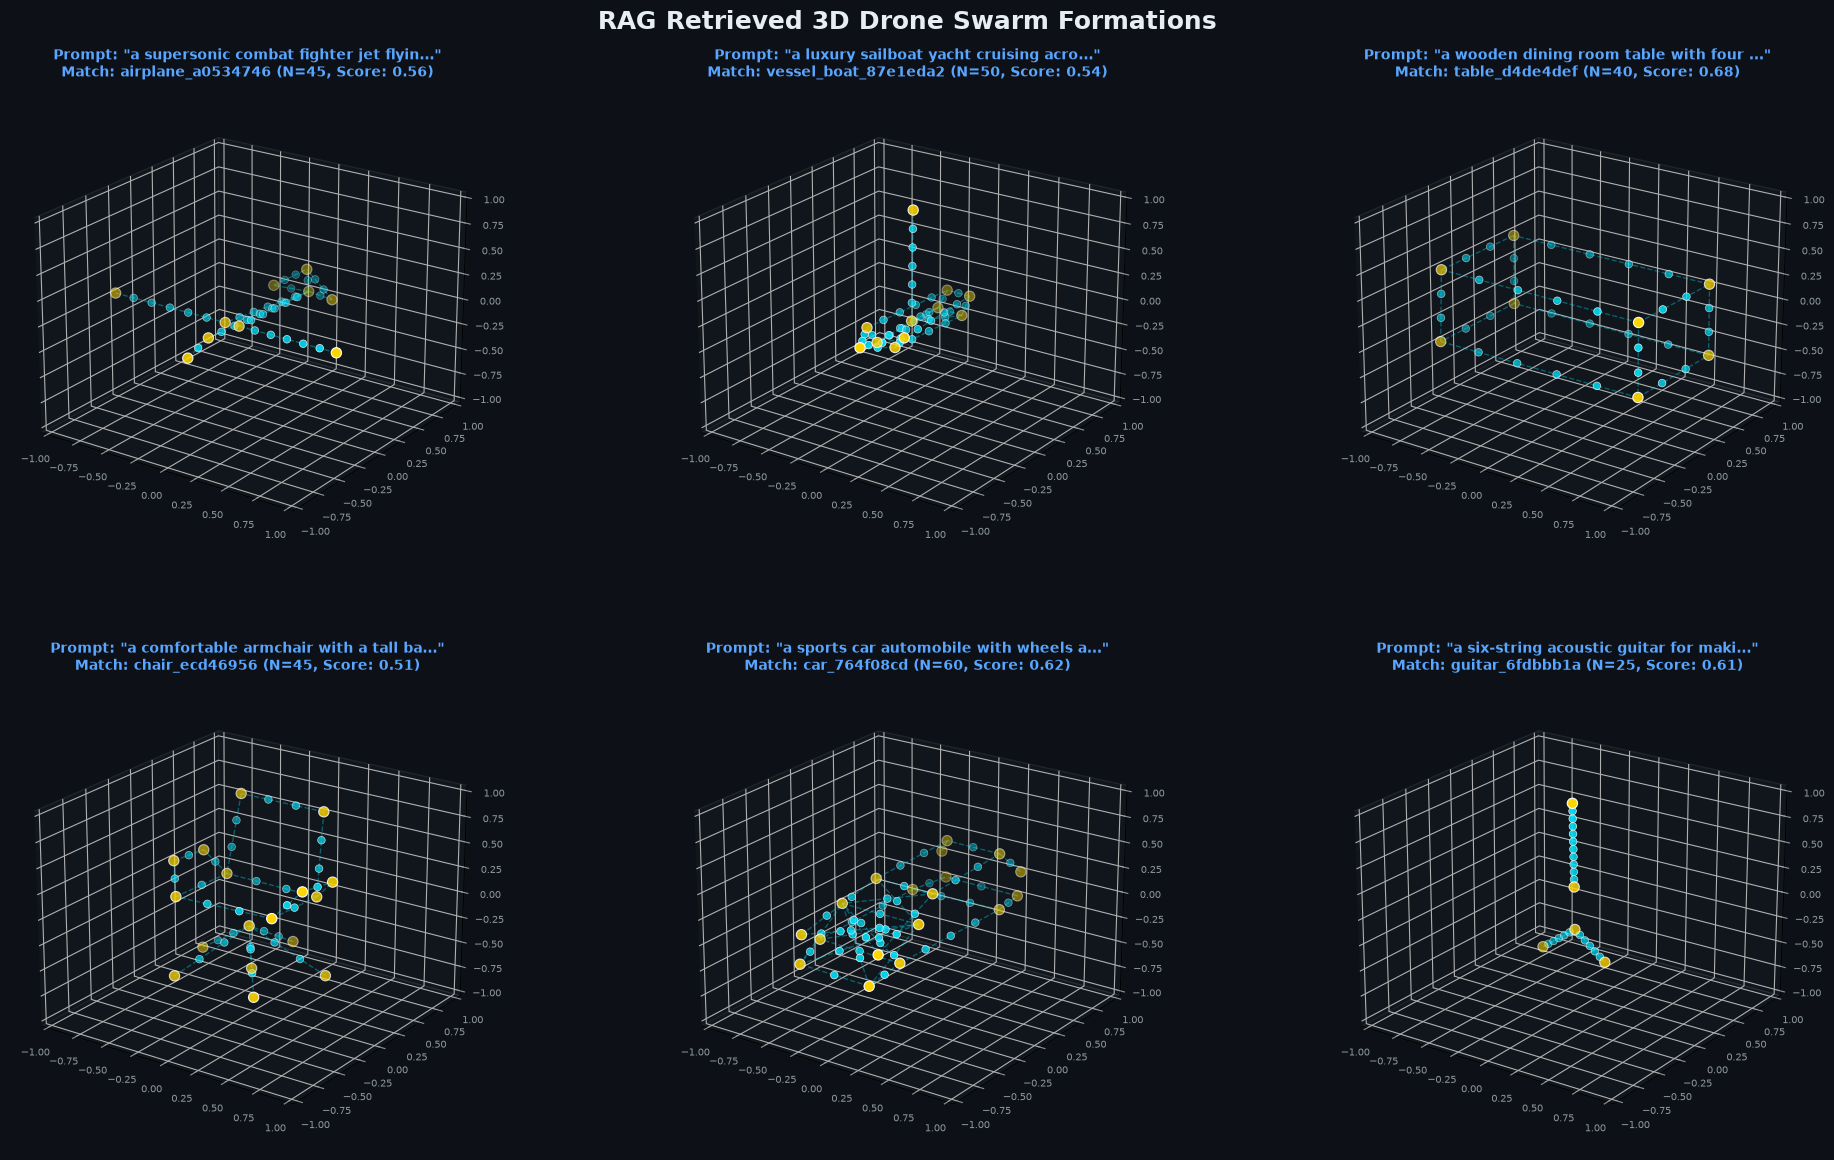

In [6]:
# Render the matched 3D formations in a side-by-side grid
n_matched = len(valid_results)
rows = (n_matched + 2) // 3
cols = min(3, n_matched)

fig = plt.figure(figsize=(20, 6 * rows), facecolor='#0D1117')
plt.subplots_adjust(wspace=0.1, hspace=0.25, top=0.92, bottom=0.03, left=0.02, right=0.98)
fig.suptitle('RAG Retrieved 3D Drone Swarm Formations', color='#E6EDF3', fontsize=18, fontweight='bold')

for idx, (prompt, res) in enumerate(valid_results):
    ax = fig.add_subplot(rows, cols, idx + 1, projection='3d', facecolor='#0D1117')
    points = res['points']
    types = res['types']
    shape = res['shape']
    anchors = np.array(shape['anchors'])
    edges = shape['edges']
    
    anchor_mask = np.array(types) == 'anchor'
    edge_mask = np.array(types) == 'edge'
    
    # Wireframe guides
    for i, j in edges:
        p1, p2 = anchors[i], anchors[j]
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color='#00E5FF', alpha=0.35, linewidth=1.0, linestyle='--')
        
    # Edge drones
    if np.sum(edge_mask) > 0:
        edge_pts = points[edge_mask]
        ax.scatter(edge_pts[:, 0], edge_pts[:, 1], edge_pts[:, 2], color='#00E5FF', s=30, edgecolors='#FFFFFF', linewidth=0.5, alpha=0.95)
        
    # Anchor drones
    anchor_pts = points[anchor_mask]
    ax.scatter(anchor_pts[:, 0], anchor_pts[:, 1], anchor_pts[:, 2], color='#FFD700', s=55, edgecolors='#FFFFFF', linewidth=0.8, alpha=1.0)
    
    short_prompt = prompt if len(prompt) < 40 else prompt[:37] + '...'
    ax.set_title(f'Prompt: "{short_prompt}"\nMatch: {res["shape_key"]} (N={res["num_drones"]}, Score: {res["score"]:.2f})',
                 color='#58A6FF', fontsize=10, fontweight='bold', pad=4)
    ax.set_xlim([-1.05, 1.05])
    ax.set_ylim([-1.05, 1.05])
    ax.set_zlim([-1.05, 1.05])
    ax.view_init(elev=22, azim=-55)
    
    ax.grid(True, linestyle=':', alpha=0.25, color='#30363D')
    ax.tick_params(colors='#8B949E', labelsize=7)
    for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
        pane.set_facecolor('#161B22')
        pane.set_edgecolor('#30363D')

plt.savefig('assets/rag_retrieved_swarms_gallery.png', dpi=150, facecolor='#0D1117')
plt.show()


USER PROMPT: "a fast two-wheeled motorcycle on the highway"
RESULT: MATCH FOUND!
  - Model ID:         motorcycle_8020984f
  - Category:         motorcycle
  - Cosine Score:     0.506
  - Minimum Anchors:  11 drones
  - Perceptual N_min: 33 drones (for human eye)
  - Target Drones:    45 drones
  - Formation built:  45 drones successfully allocated.



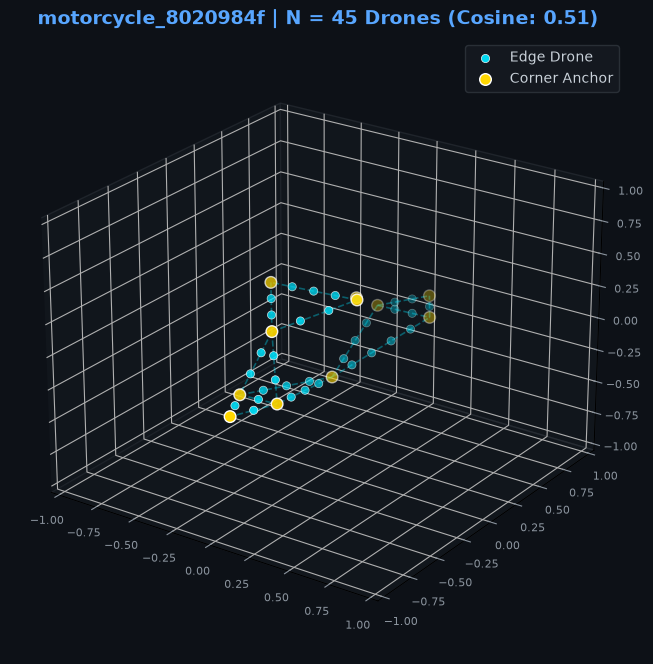

In [7]:
# --- TRY YOUR OWN CUSTOM PROMPT HERE ---
MY_PROMPT = 'a fast two-wheeled motorcycle on the highway'
MY_DRONES = 45 # Set to None to use automatic perceptual minimum

my_result = query_and_generate(MY_PROMPT, num_drones=MY_DRONES)
render_swarm_matplotlib(my_result)
